# Lesson 1 — South African Underwater Acoustic Data

## Zindi French Embassy Underwater Vessel Noise Challenge

### Objectives

1. Understand the structure of the acoustic dataset.
2. Investigate the ten monitoring stations.
3. Examine recording equipment and sampling coverage.
4. Identify missing data and unusual measurements.
5. Understand acoustic energy expressed in decibels.
6. Establish a foundation for synthetic vessel-noise modelling.

### Competition boundary

This notebook analyzes the released South African acoustic archive.

Test.csv is inference-only and will not be used for model training,
calibration, pseudo-labelling or synthetic training-data generation.


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd().resolve().parent
DATA_DIR = PROJECT_ROOT / "data" / "zindi" / "extracted"
REPORT_DIR = PROJECT_ROOT / "reports" / "eda"

REPORT_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Data directory exists:", DATA_DIR.exists())

parquet_files = sorted(DATA_DIR.rglob("*.parquet"))

print("Parquet files discovered:", len(parquet_files))

for path in parquet_files:
    print(path.relative_to(DATA_DIR))


Project root: /Users/qwaku/Codes/QBE/Zindi/french-embassy-underwater-vessel-noise-challenge
Data directory exists: True
Parquet files discovered: 10
acoustics/01_Richards_Bay.parquet
acoustics/02_Durban.parquet
acoustics/03_Cape_Recife.parquet
acoustics/04_Bird_Island.parquet
acoustics/05_St_Croix_Island.parquet
acoustics/06_Riy_Banks.parquet
acoustics/07_St_Francis.parquet
acoustics/09_Fish_Hoek.parquet
acoustics/10_Sea_Point.parquet
acoustics/13_Saldhana_Bay.parquet


In [2]:
# Inspect schema without loading the entire dataset.
first_file = parquet_files[0]

pf = pq.ParquetFile(first_file)

print("File:", first_file.name)
print("Rows:", pf.metadata.num_rows)
print("Columns:", pf.metadata.num_columns)

print("\nColumn names:")
for col in pf.schema_arrow.names:
    print(col)

# Read a small batch for exploration.
batch = next(pf.iter_batches(batch_size=1000))
sample = batch.to_pandas()

display(sample.head())
print("\nSample dimensions:", sample.shape)


File: 01_Richards_Bay.parquet
Rows: 1001174
Columns: 74

Column names:
site
recorder
station_token
sample_rate_hz
file_kind
src_file
file_date
t
dur
TOL_0.8
TOL_1
TOL_1.3
TOL_1.6
TOL_2
TOL_2.5
TOL_3.2
TOL_4
TOL_5
TOL_6.3
TOL_7.9
TOL_10
TOL_12.6
TOL_15.8
TOL_20
TOL_25.1
TOL_31.6
TOL_39.8
TOL_50.1
TOL_63.1
TOL_79.4
TOL_100
TOL_125.9
TOL_158.5
TOL_199.5
TOL_251.2
TOL_316.2
TOL_398.1
TOL_501.2
TOL_631
TOL_794.3
TOL_1000
TOL_1258.9
TOL_1584.9
TOL_1995.3
TOL_2511.9
TOL_3162.3
TOL_3981.1
TOL_5011.9
TOL_6309.6
TOL_7943.3
TOL_10000
TOL_12000
TOL_12589.3
TOL_15848.9
TOL_19952.6
TOL_24000
TOL_25118.9
TOL_31622.8
TOL_39810.7
TOL_48000
TOL_50118.7
TOL_63095.7
TOL_72000
TOL_79432.8
TOL_100000
TOL_125892.5
TOL_158489.3
TOL_192000
TOL_199526.2
TOL_251188.6
TOL_288000
qc_duration_ge55
qc_25band_finite
qc_25band_spread_ge6


,site,recorder,station_token,sample_rate_hz,file_kind,src_file,file_date,t,dur,TOL_0.8,...,TOL_100000,TOL_125892.5,TOL_158489.3,TOL_192000,TOL_199526.2,TOL_251188.6,TOL_288000,qc_duration_ge55,qc_25band_finite,qc_25band_spread_ge6
0,1 Richards Bay,201383949_Richards_Bay_201383949.1.24000,201383949,24000,MinRes,201383949_Richards_Bay_201383949.1.24000_20170...,20170509,2017-05-09 00:00:02,58.0,131.600006,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,True,True,True
1,1 Richards Bay,201383949_Richards_Bay_201383949.1.24000,201383949,24000,MinRes,201383949_Richards_Bay_201383949.1.24000_20170...,20170509,2017-05-09 00:01:00,60.0,131.199997,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,True,True,True
2,1 Richards Bay,201383949_Richards_Bay_201383949.1.24000,201383949,24000,MinRes,201383949_Richards_Bay_201383949.1.24000_20170...,20170509,2017-05-09 00:02:00,60.0,131.199997,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,True,True,True
3,1 Richards Bay,201383949_Richards_Bay_201383949.1.24000,201383949,24000,MinRes,201383949_Richards_Bay_201383949.1.24000_20170...,20170509,2017-05-09 00:03:00,60.0,131.199997,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,True,True,True
4,1 Richards Bay,201383949_Richards_Bay_201383949.1.24000,201383949,24000,MinRes,201383949_Richards_Bay_201383949.1.24000_20170...,20170509,2017-05-09 00:04:00,60.0,131.199997,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,True,True,True



Sample dimensions: (1000, 74)


In [3]:
print("Column types:")
display(sample.dtypes.to_frame("dtype"))

print("\nNumeric columns:")
numeric_columns = sample.select_dtypes(
    include="number"
).columns.tolist()

print(numeric_columns)
print("Numeric column count:", len(numeric_columns))


Column types:


,dtype
site,str
recorder,str
station_token,str
sample_rate_hz,int32
file_kind,str
...,...
TOL_251188.6,float32
TOL_288000,float32
qc_duration_ge55,bool
qc_25band_finite,bool



Numeric columns:
['sample_rate_hz', 'dur', 'TOL_0.8', 'TOL_1', 'TOL_1.3', 'TOL_1.6', 'TOL_2', 'TOL_2.5', 'TOL_3.2', 'TOL_4', 'TOL_5', 'TOL_6.3', 'TOL_7.9', 'TOL_10', 'TOL_12.6', 'TOL_15.8', 'TOL_20', 'TOL_25.1', 'TOL_31.6', 'TOL_39.8', 'TOL_50.1', 'TOL_63.1', 'TOL_79.4', 'TOL_100', 'TOL_125.9', 'TOL_158.5', 'TOL_199.5', 'TOL_251.2', 'TOL_316.2', 'TOL_398.1', 'TOL_501.2', 'TOL_631', 'TOL_794.3', 'TOL_1000', 'TOL_1258.9', 'TOL_1584.9', 'TOL_1995.3', 'TOL_2511.9', 'TOL_3162.3', 'TOL_3981.1', 'TOL_5011.9', 'TOL_6309.6', 'TOL_7943.3', 'TOL_10000', 'TOL_12000', 'TOL_12589.3', 'TOL_15848.9', 'TOL_19952.6', 'TOL_24000', 'TOL_25118.9', 'TOL_31622.8', 'TOL_39810.7', 'TOL_48000', 'TOL_50118.7', 'TOL_63095.7', 'TOL_72000', 'TOL_79432.8', 'TOL_100000', 'TOL_125892.5', 'TOL_158489.3', 'TOL_192000', 'TOL_199526.2', 'TOL_251188.6', 'TOL_288000']
Numeric column count: 64


,missing_percent
TOL_25118.9,100.0
TOL_100000,100.0
TOL_12000,100.0
TOL_31622.8,100.0
TOL_39810.7,100.0
TOL_48000,100.0
TOL_50118.7,100.0
TOL_72000,100.0
TOL_79432.8,100.0
TOL_63095.7,100.0


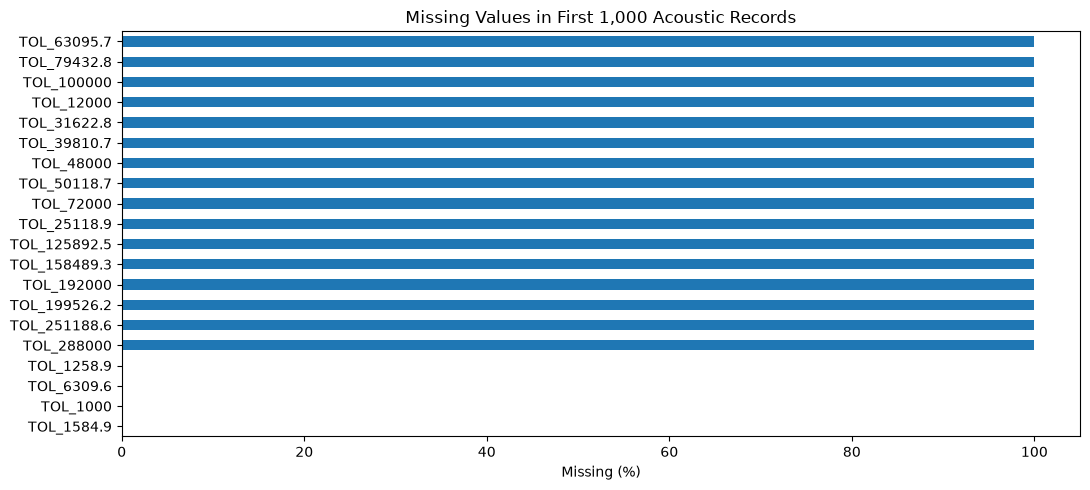

In [5]:
missing = (
    sample.isna()
    .mean()
    .mul(100)
    .sort_values(ascending=False)
)

display(
    missing.head(25).to_frame("missing_percent")
)

fig, ax = plt.subplots(figsize=(11, 5))

missing.head(20).sort_values().plot(
    kind="barh",
    ax=ax
)

ax.set_title("Missing Values in First 1,000 Acoustic Records")
ax.set_xlabel("Missing (%)")

plt.tight_layout()
plt.show()


In [6]:
levels_db = np.array([60, 70, 80, 90], dtype=float)

relative_energy = 10 ** (levels_db / 10)

example = pd.DataFrame({
    "Level (dB)": levels_db,
    "Relative energy": relative_energy
})

example["Energy ratio to 60 dB"] = (
    example["Relative energy"] /
    example["Relative energy"].iloc[0]
)

display(example)


,Level (dB),Relative energy,Energy ratio to 60 dB
0,60.0,1.000000e+06,1.0
1,70.0,1.000000e+07,10.0
2,80.0,1.000000e+08,100.0
3,90.0,1.000000e+09,1000.0


## 2. Comparing All Ten Acoustic Monitoring Stations

,file,rows,columns,band_columns,first_timestamp,last_timestamp,pct_missing_bands,rows_duration_under55,rows_duration_not60,recorders
0,acoustics/01_Richards_Bay.parquet,1001174,74,62,2017-05-09 00:00:02,2024-05-25 23:59:00,23.578,15691,27415,3
1,acoustics/02_Durban.parquet,44640,74,62,2025-10-28 00:00:00,2025-12-06 23:59:00,30.645,0,16,1
2,acoustics/03_Cape_Recife.parquet,5928,74,62,2024-03-05 00:00:00,2024-03-23 23:12:00,25.806,0,0,1
3,acoustics/04_Bird_Island.parquet,47552,74,62,2022-03-21 05:59:58,2024-06-29 23:59:00,30.718,32,60,2
4,acoustics/05_St_Croix_Island.parquet,250717,74,62,2022-04-05 00:00:00,2025-09-20 06:00:00,31.728,130,282,3
5,acoustics/06_Riy_Banks.parquet,4121,74,62,2024-03-05 00:00:00,2024-04-05 23:12:00,25.806,0,0,1
6,acoustics/07_St_Francis.parquet,169488,74,62,2015-04-21 00:00:00,2018-02-28 14:24:00,25.806,1,2,1
7,acoustics/09_Fish_Hoek.parquet,53767,74,62,2016-09-13 00:00:02,2021-09-28 12:45:00,21.373,1014,8296,2
8,acoustics/10_Sea_Point.parquet,3660,74,62,2018-10-11 10:00:02,2018-10-13 23:59:00,17.742,0,2,1
9,acoustics/13_Saldhana_Bay.parquet,134732,74,62,2022-03-22 00:00:00,2023-05-29 04:34:00,25.806,28,161,2


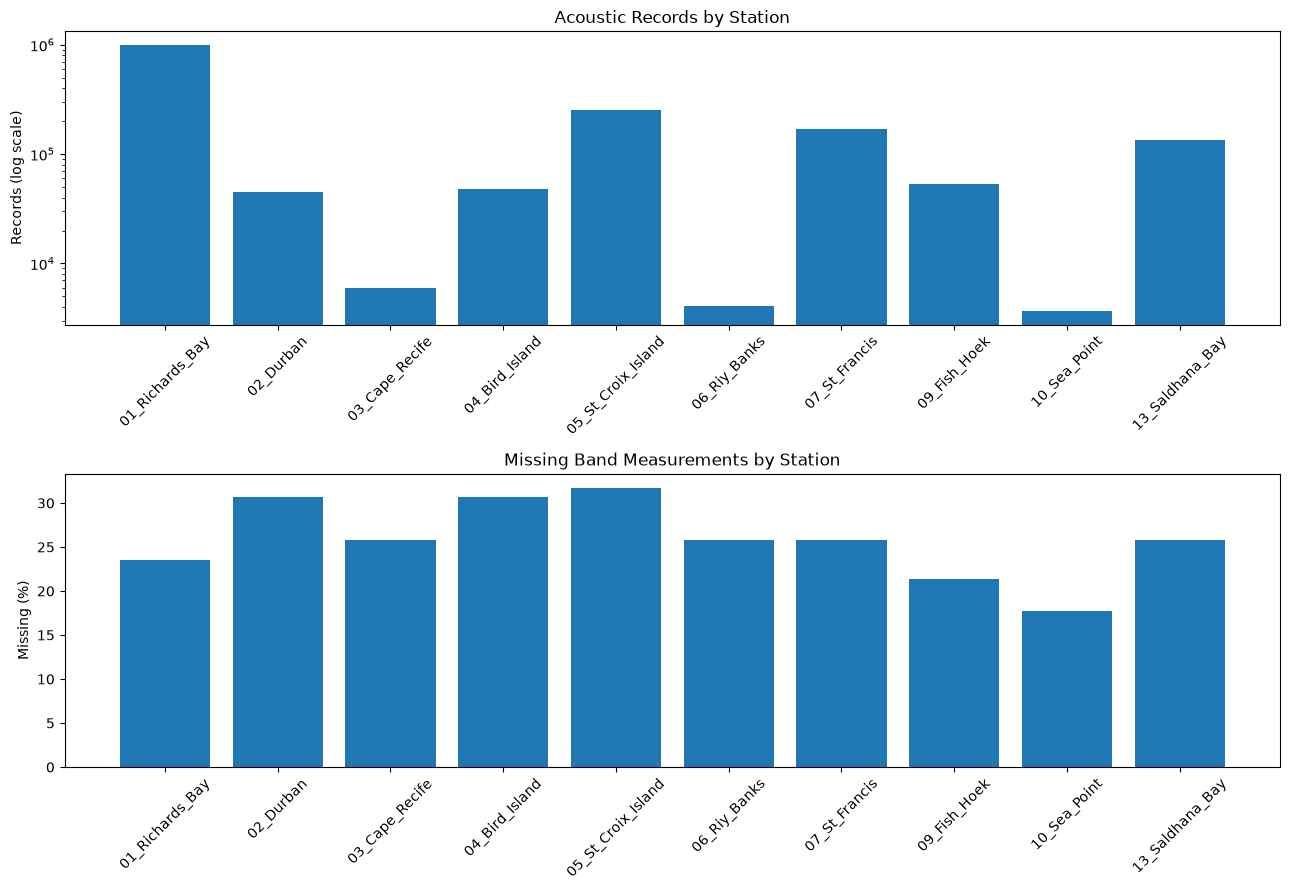

In [7]:
# Read the station-level audit we already generated.
audit_path = (
    PROJECT_ROOT
    / "reports"
    / "zindi_audit"
    / "station_acoustic_audit.csv"
)

station_audit = pd.read_csv(audit_path)

display(station_audit)

# Visualize station recording coverage.
station_audit["station"] = (
    station_audit["file"]
    .str.replace(".parquet", "", regex=False)
    .str.split("/")
    .str[-1]
)

fig, axes = plt.subplots(2, 1, figsize=(13, 9))

# Number of recordings per station.
axes[0].bar(
    station_audit["station"],
    station_audit["rows"]
)

axes[0].set_yscale("log")
axes[0].set_title("Acoustic Records by Station")
axes[0].set_ylabel("Records (log scale)")
axes[0].tick_params(axis="x", rotation=45)

# Missing acoustic band percentage.
axes[1].bar(
    station_audit["station"],
    station_audit["pct_missing_bands"]
)

axes[1].set_title("Missing Band Measurements by Station")
axes[1].set_ylabel("Missing (%)")
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()


In [8]:
total_records = station_audit["rows"].sum()

station_audit["share_of_records_pct"] = (
    100 * station_audit["rows"] / total_records
)

summary = station_audit[
    ["station", "rows", "share_of_records_pct", "recorders"]
].sort_values("rows", ascending=False)

display(summary)

print(f"Total records: {total_records:,}")

print(
    "Largest station share:",
    f"{summary['share_of_records_pct'].iloc[0]:.2f}%"
)

,station,rows,share_of_records_pct,recorders
0,01_Richards_Bay,1001174,58.350988,3
4,05_St_Croix_Island,250717,14.612430,3
6,07_St_Francis,169488,9.878195,1
9,13_Saldhana_Bay,134732,7.852526,2
7,09_Fish_Hoek,53767,3.133679,2
3,04_Bird_Island,47552,2.771453,2
1,02_Durban,44640,2.601734,1
2,03_Cape_Recife,5928,0.345499,1
5,06_Riy_Banks,4121,0.240182,1
8,10_Sea_Point,3660,0.213314,1


Total records: 1,715,779
Largest station share: 58.35%


## 3. Identifying the Competition's 25 Frequency Bands

In [9]:
# Read only the CSV header: no test measurements are loaded.
test_path = PROJECT_ROOT / "data" / "zindi" / "raw" / "Test.csv"

test_columns = pd.read_csv(test_path, nrows=0).columns.tolist()

print("Total test columns:", len(test_columns))

feature_columns = [
    col for col in test_columns if col != "ID"
]

print("Acoustic features:", len(feature_columns))

print("\nFirst 20 features:")
print(feature_columns[:20])

print("\nLast 20 features:")
print(feature_columns[-20:])

Total test columns: 376
Acoustic features: 375

First 20 features:
['m01_TOL_31.6', 'm01_TOL_39.8', 'm01_TOL_50.1', 'm01_TOL_63.1', 'm01_TOL_79.4', 'm01_TOL_100', 'm01_TOL_125.9', 'm01_TOL_158.5', 'm01_TOL_199.5', 'm01_TOL_251.2', 'm01_TOL_316.2', 'm01_TOL_398.1', 'm01_TOL_501.2', 'm01_TOL_631', 'm01_TOL_794.3', 'm01_TOL_1000', 'm01_TOL_1258.9', 'm01_TOL_1584.9', 'm01_TOL_1995.3', 'm01_TOL_2511.9']

Last 20 features:
['m15_TOL_100', 'm15_TOL_125.9', 'm15_TOL_158.5', 'm15_TOL_199.5', 'm15_TOL_251.2', 'm15_TOL_316.2', 'm15_TOL_398.1', 'm15_TOL_501.2', 'm15_TOL_631', 'm15_TOL_794.3', 'm15_TOL_1000', 'm15_TOL_1258.9', 'm15_TOL_1584.9', 'm15_TOL_1995.3', 'm15_TOL_2511.9', 'm15_TOL_3162.3', 'm15_TOL_3981.1', 'm15_TOL_5011.9', 'm15_TOL_6309.6', 'm15_TOL_7943.3']


In [10]:
import re

# Extract possible frequency labels from test feature names.
frequencies = set()

for col in feature_columns:
    matches = re.findall(r"TOL_([0-9]+(?:\.[0-9]+)?)", col)
    frequencies.update(matches)

frequencies = sorted(frequencies, key=float)

print("Frequency bands discovered:", len(frequencies))
print(frequencies)


Frequency bands discovered: 25
['31.6', '39.8', '50.1', '63.1', '79.4', '100', '125.9', '158.5', '199.5', '251.2', '316.2', '398.1', '501.2', '631', '794.3', '1000', '1258.9', '1584.9', '1995.3', '2511.9', '3162.3', '3981.1', '5011.9', '6309.6', '7943.3']


In [11]:
archive_band_columns = [
    col for col in sample.columns
    if col.startswith("TOL_")
]

expected_band_columns = [
    f"TOL_{freq}" for freq in frequencies
]

available = [
    col for col in expected_band_columns
    if col in archive_band_columns
]

missing = [
    col for col in expected_band_columns
    if col not in archive_band_columns
]

print("Expected competition bands:", len(expected_band_columns))
print("Available in archive:", len(available))
print("Unavailable in archive:", missing)

Expected competition bands: 25
Available in archive: 25
Unavailable in archive: []


## 4. Competition Band Coverage Across All Stations

In [12]:
# Analyze the exact 25 competition bands across all stations.
# Process one Parquet batch at a time to limit memory use.

band_columns = expected_band_columns

coverage_records = []

for file in parquet_files:
    parquet = pq.ParquetFile(file)
    total = 0
    valid_counts = np.zeros(len(band_columns), dtype=np.int64)

    for batch in parquet.iter_batches(
        batch_size=50000,
        columns=band_columns
    ):
        values = batch.to_pandas()[band_columns].to_numpy(
            dtype=np.float64
        )

        valid_counts += np.isfinite(values).sum(axis=0)
        total += values.shape[0]

    for band, valid_count in zip(
        band_columns, valid_counts
    ):
        coverage_records.append({
            "station": file.stem,
            "band": band,
            "total_rows": total,
            "valid_rows": int(valid_count),
            "coverage_pct": (
                100 * valid_count / total if total else np.nan
            )
        })

coverage_df = pd.DataFrame(coverage_records)

coverage_matrix = coverage_df.pivot(
    index="station",
    columns="band",
    values="coverage_pct"
)[band_columns]

display(coverage_matrix.round(2))

band,TOL_31.6,TOL_39.8,TOL_50.1,TOL_63.1,TOL_79.4,TOL_100,TOL_125.9,TOL_158.5,TOL_199.5,TOL_251.2,...,TOL_1000,TOL_1258.9,TOL_1584.9,TOL_1995.3,TOL_2511.9,TOL_3162.3,TOL_3981.1,TOL_5011.9,TOL_6309.6,TOL_7943.3
station,,,,,,,,,,,,,,,,,,,,,
01_Richards_Bay,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,...,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0
02_Durban,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,...,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0
03_Cape_Recife,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,...,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0
04_Bird_Island,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,...,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0
05_St_Croix_Island,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,...,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0
06_Riy_Banks,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,...,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0
07_St_Francis,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,...,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0
09_Fish_Hoek,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,...,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0
10_Sea_Point,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,...,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0


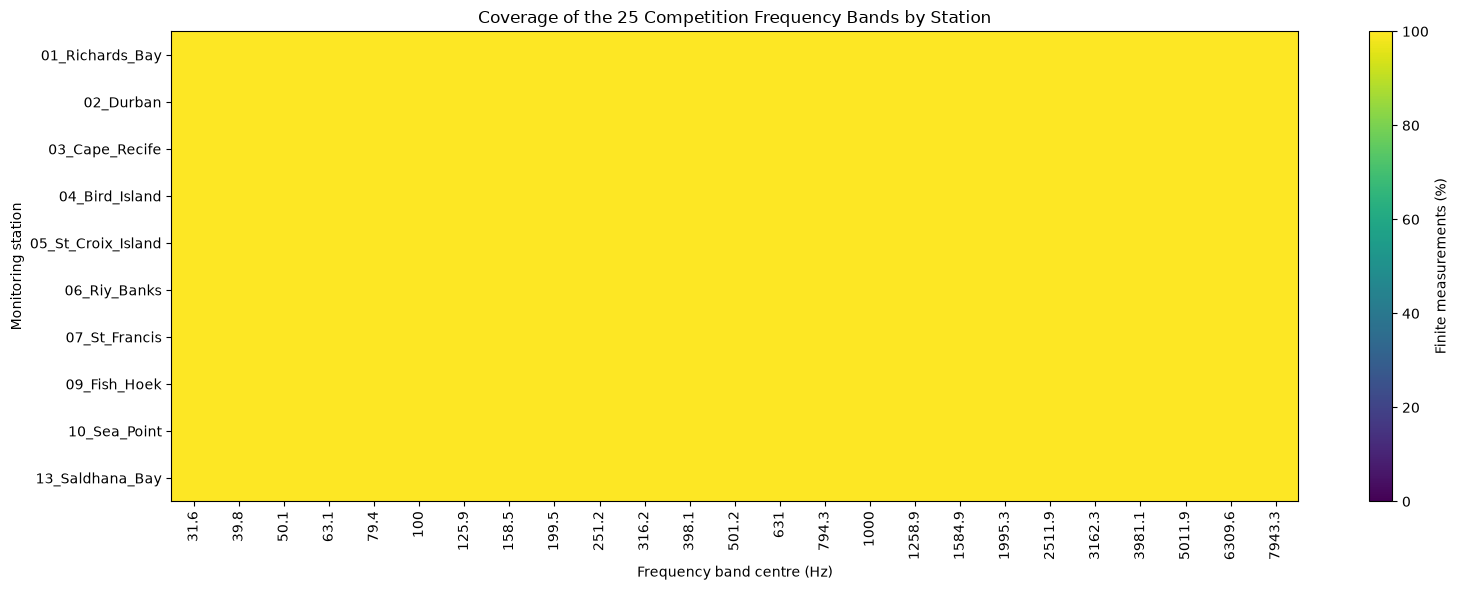

In [13]:
fig, ax = plt.subplots(figsize=(16, 6))

im = ax.imshow(
    coverage_matrix.to_numpy(),
    aspect="auto",
    vmin=0,
    vmax=100,
    cmap="viridis"
)

ax.set_xticks(range(len(band_columns)))
ax.set_xticklabels(
    [b.replace("TOL_", "") for b in band_columns],
    rotation=90
)

ax.set_yticks(range(len(coverage_matrix)))
ax.set_yticklabels(coverage_matrix.index)

ax.set_title(
    "Coverage of the 25 Competition Frequency Bands by Station"
)
ax.set_xlabel("Frequency band centre (Hz)")
ax.set_ylabel("Monitoring station")

fig.colorbar(im, ax=ax, label="Finite measurements (%)")

plt.tight_layout()
plt.show()


In [14]:
complete_records = []

for file in parquet_files:
    parquet = pq.ParquetFile(file)

    total_rows = 0
    complete_rows = 0

    for batch in parquet.iter_batches(
        batch_size=50000,
        columns=band_columns
    ):
        values = batch.to_pandas().to_numpy(
            dtype=np.float64
        )

        finite = np.isfinite(values)

        total_rows += len(values)
        complete_rows += finite.all(axis=1).sum()

    complete_records.append({
        "station": file.stem,
        "total_rows": total_rows,
        "complete_25_band_rows": int(complete_rows),
        "complete_pct": (
            100 * complete_rows / total_rows
            if total_rows else np.nan
        )
    })

complete_df = pd.DataFrame(complete_records)

display(
    complete_df.sort_values(
        "complete_pct",
        ascending=False
    )
)

print(
    "Overall complete 25-band coverage:",
    f"{100 * complete_df['complete_25_band_rows'].sum() / complete_df['total_rows'].sum():.2f}%"
)


,station,total_rows,complete_25_band_rows,complete_pct
0,01_Richards_Bay,1001174,1001174,100.0
1,02_Durban,44640,44640,100.0
2,03_Cape_Recife,5928,5928,100.0
3,04_Bird_Island,47552,47552,100.0
4,05_St_Croix_Island,250717,250717,100.0
5,06_Riy_Banks,4121,4121,100.0
6,07_St_Francis,169488,169488,100.0
7,09_Fish_Hoek,53767,53767,100.0
8,10_Sea_Point,3660,3660,100.0
9,13_Saldhana_Bay,134732,134732,100.0


Overall complete 25-band coverage: 100.00%


## 5. Temporal Continuity and 15-Minute Background Window Availability

In [15]:
# Analyze temporal continuity without loading acoustic band values.
# Only timestamps, recorder IDs and durations are read.

continuity_records = []

for file in parquet_files:
    station = file.stem

    df = pd.read_parquet(
        file,
        columns=["recorder", "t", "dur"]
    )

    df["t"] = pd.to_datetime(df["t"])

    station_valid_windows = 0
    station_continuous_runs = 0
    station_duplicates = 0
    station_short_duration = 0
    station_max_run = 0

    for recorder, group in df.groupby("recorder"):
        group = group.sort_values("t").reset_index(drop=True)

        duplicate = group["t"].duplicated(keep=False)
        station_duplicates += int(duplicate.sum())

        # Use only full or nearly full minute measurements.
        valid_duration = (
            group["dur"].ge(55)
            & group["dur"].le(65)
        )

        station_short_duration += int(
            (~valid_duration).sum()
        )

        # Allow small timestamp offsets caused by exports.
        delta_seconds = group["t"].diff().dt.total_seconds()

        continuous_edge = delta_seconds.between(
            58, 62, inclusive="both"
        )

        # Separate runs at timestamp gaps, invalid durations
        # and duplicate timestamps.
        previous_valid = valid_duration.shift(
            1, fill_value=False
        )

        run_start = ~(
            continuous_edge
            & valid_duration
            & previous_valid
            & ~duplicate
            & ~duplicate.shift(1, fill_value=False)
        )

        run_id = run_start.cumsum()

        valid_group = group.loc[
            valid_duration & ~duplicate
        ].copy()

        valid_group["run_id"] = run_id.loc[
            valid_duration & ~duplicate
        ].to_numpy()

        run_lengths = valid_group.groupby("run_id").size()

        station_continuous_runs += len(run_lengths)

        if len(run_lengths):
            station_max_run = max(
                station_max_run,
                int(run_lengths.max())
            )

            # Conservative, non-overlapping 15-minute windows.
            station_valid_windows += int(
                (run_lengths // 15).sum()
            )

    continuity_records.append({
        "station": station,
        "records": len(df),
        "duplicate_timestamp_rows": station_duplicates,
        "invalid_duration_rows": station_short_duration,
        "continuous_runs": station_continuous_runs,
        "longest_run_minutes": station_max_run,
        "nonoverlapping_15min_windows": station_valid_windows
    })

continuity_df = pd.DataFrame(continuity_records)

display(
    continuity_df.sort_values(
        "nonoverlapping_15min_windows",
        ascending=False
    )
)

print(
    "Total candidate non-overlapping windows:",
    f"{continuity_df['nonoverlapping_15min_windows'].sum():,}"
)

,station,records,duplicate_timestamp_rows,invalid_duration_rows,continuous_runs,longest_run_minutes,nonoverlapping_15min_windows
0,01_Richards_Bay,1001174,0,15713,15045,9664,52522
4,05_St_Croix_Island,250717,0,130,137,83040,16697
9,13_Saldhana_Bay,134732,0,28,303,1139,8868
6,07_St_Francis,169488,0,1,27154,15,3371
3,04_Bird_Island,47552,0,32,36,1440,3168
1,02_Durban,44640,0,0,2,37440,2976
7,09_Fish_Hoek,53767,0,1014,9765,1079,297
8,10_Sea_Point,3660,0,0,2,3300,244
2,03_Cape_Recife,5928,0,0,456,13,0
5,06_Riy_Banks,4121,0,0,317,13,0


Total candidate non-overlapping windows: 88,143


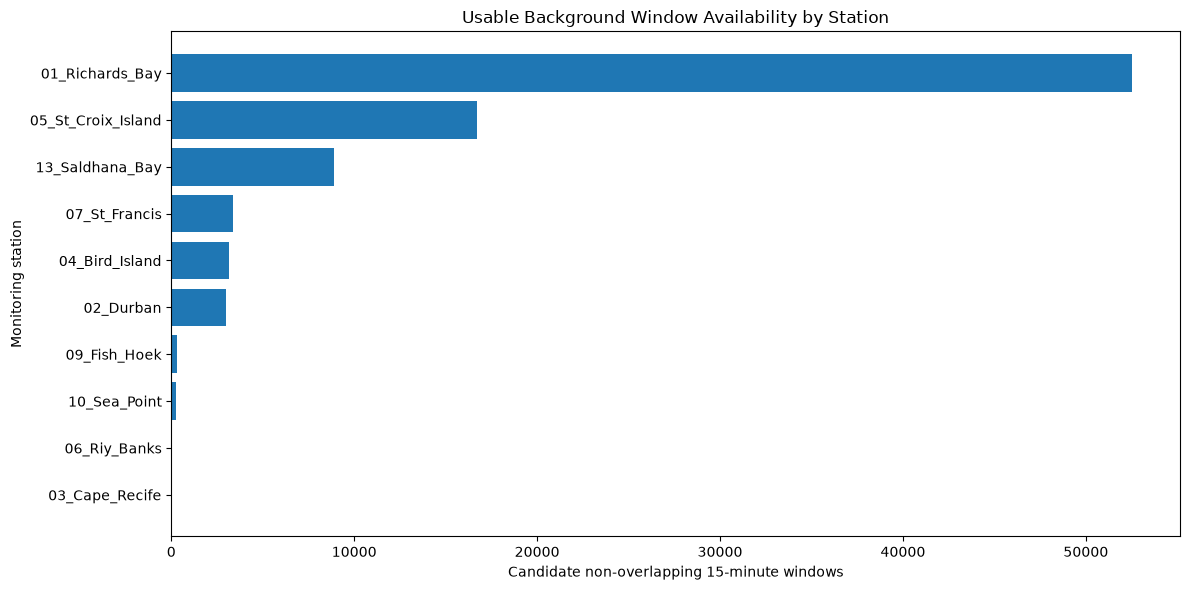

In [16]:
plot_df = continuity_df.sort_values(
    "nonoverlapping_15min_windows",
    ascending=True
)

fig, ax = plt.subplots(figsize=(12, 6))

ax.barh(
    plot_df["station"],
    plot_df["nonoverlapping_15min_windows"]
)

ax.set_xlabel("Candidate non-overlapping 15-minute windows")
ax.set_ylabel("Monitoring station")
ax.set_title("Usable Background Window Availability by Station")

plt.tight_layout()
plt.show()

In [17]:
output_path = REPORT_DIR / "temporal_continuity_summary.csv"

continuity_df.to_csv(output_path, index=False)

print("Saved:", output_path)

Saved: /Users/qwaku/Codes/QBE/Zindi/french-embassy-underwater-vessel-noise-challenge/reports/eda/temporal_continuity_summary.csv


## 6. Recording Interval Diagnostics

In [18]:
# Diagnose timestamp spacing and recording durations.
# Read metadata only; do not load acoustic measurements.

diagnostic_rows = []

for file in parquet_files:
    df = pd.read_parquet(
        file,
        columns=["recorder", "t", "dur"]
    )

    df["t"] = pd.to_datetime(df["t"], errors="coerce")

    for recorder, group in df.groupby("recorder", dropna=False):
        group = group.sort_values("t")

        delta = (
            group["t"]
            .diff()
            .dt.total_seconds()
            .dropna()
        )

        duration = pd.to_numeric(
            group["dur"], errors="coerce"
        )

        # Inspect the most common rounded timestamp intervals.
        common_intervals = (
            delta.round()
            .value_counts()
            .head(5)
        )

        diagnostic_rows.append({
            "station": file.stem,
            "recorder": str(recorder),
            "records": len(group),
            "median_interval_sec": delta.median(),
            "pct_intervals_58_62": (
                100 * delta.between(58, 62).mean()
                if len(delta) else np.nan
            ),
            "pct_intervals_55_65": (
                100 * delta.between(55, 65).mean()
                if len(delta) else np.nan
            ),
            "median_duration_sec": duration.median(),
            "duration_min_sec": duration.min(),
            "duration_max_sec": duration.max(),
            "common_intervals_sec": ", ".join(
                f"{interval:g}s:{count}"
                for interval, count in common_intervals.items()
            )
        })

interval_df = pd.DataFrame(diagnostic_rows)

display(
    interval_df.sort_values(
        ["station", "recorder"]
    )
)

interval_df.to_csv(
    REPORT_DIR / "recorder_interval_diagnostics.csv",
    index=False
)

print("Recorder configurations:", len(interval_df))

,station,recorder,records,median_interval_sec,pct_intervals_58_62,pct_intervals_55_65,median_duration_sec,duration_min_sec,duration_max_sec,common_intervals_sec
0,01_Richards_Bay,201383949_Richards_Bay_201383949.1.24000,492310,60.0,99.746704,99.753204,60.0,1.0,360.0,"60s:480468, 58s:5331, 62s:5251, 29s:392, 91s:391"
1,01_Richards_Bay,5708_Richards_Bay_5708.1.24000,160798,60.0,97.754311,97.962027,60.0,1.0,71.0,"60s:156363, 120s:754, 58s:400, 62s:393, 45s:117"
2,01_Richards_Bay,7005_Richards_Bay_7005.1.24000,348066,60.0,96.753767,96.972405,60.0,2.0,60.0,"60s:336467, 2s:4825, 118s:4822, 89s:426, 31s:426"
3,02_Durban,8230_ST600_8230.1.48000,44640,60.0,99.997760,99.997760,60.0,59.0,60.0,"60s:44632, 61s:3, 59s:3, 777660s:1"
4,03_Cape_Recife,8210_ST600_8210.1.48000,5928,60.0,92.323266,92.323266,60.0,60.0,60.0,"60s:5472, 2880s:455"
5,04_Bird_Island,URN.BirdIsland.2022_6509.1.24000,46472,60.0,99.857976,99.857976,60.0,2.0,60.0,"60s:46405, 2s:32, 86458s:27, 842460s:3, 1.0368..."
6,04_Bird_Island,URN_8321_8321.1.12000,1080,60.0,100.000000,100.000000,60.0,58.0,60.0,60s:1079
7,05_St_Croix_Island,URN.BirdIsland.2022_6509.1.24000,45163,60.0,99.869359,99.869359,60.0,2.0,60.0,"60s:45097, 2s:26, 86458s:23, 86402s:6, 58s:6"
8,05_St_Croix_Island,URN.StCroix.2022_6509.1.24000,70116,60.0,99.864508,99.864508,60.0,2.0,60.0,"60s:70013, 2s:43, 86458s:38, 58s:7, 86402s:6"
9,05_St_Croix_Island,URN_8321_8321.1.12000,135438,60.0,99.960129,99.964559,60.0,2.0,60.0,"60s:135353, 58s:30, 86402s:26, 86403s:6, 57s:6"


Recorder configurations: 17


In [19]:
suspicious = interval_df[
    interval_df["station"].str.contains(
        "Cape_Recife|Riy_Banks|St_Francis|Fish_Hoek",
        regex=True
    )
]

display(
    suspicious[
        [
            "station",
            "recorder",
            "records",
            "median_interval_sec",
            "pct_intervals_58_62",
            "median_duration_sec",
            "common_intervals_sec"
        ]
    ]
)

,station,recorder,records,median_interval_sec,pct_intervals_58_62,median_duration_sec,common_intervals_sec
4,03_Cape_Recife,8210_ST600_8210.1.48000,5928,60.0,92.323266,60.0,"60s:5472, 2880s:455"
10,06_Riy_Banks,8230_ST600_8230.1.48000,4121,60.0,92.330097,60.0,"60s:3804, 2880s:296, 6480s:17, 780480s:2, 1008..."
11,07_St_Francis,SM2M_Cape_StFrancis_SM2M.1.48000,169488,60.0,83.979302,60.0,"60s:142334, 960s:23759, 2760s:3362, 778560s:10..."
12,09_Fish_Hoek,ST300_201650217_ST201650217.1.96000,49260,60.0,79.179439,60.0,"60s:32149, 58s:6852, 362s:6840, 360s:2383, 49s..."
13,09_Fish_Hoek,ST300_5344_ST5344.1.96000,4507,60.0,99.800266,60.0,"60s:4491, 120s:5, 61s:3, 59s:3, 25s:2"


## 7. Continuous Recording Run-Length Distribution

In [20]:
# Summarize continuous run lengths by station.
# No acoustic measurements or test labels are loaded.

run_summaries = []
run_details = []

for file in parquet_files:
    df = pd.read_parquet(
        file,
        columns=["recorder", "t", "dur"]
    )

    df["t"] = pd.to_datetime(df["t"], errors="coerce")
    df["dur"] = pd.to_numeric(df["dur"], errors="coerce")

    for recorder, group in df.groupby(
        "recorder", dropna=False
    ):
        group = group.sort_values("t").reset_index(drop=True)

        valid = group["t"].notna() & group["dur"].between(
            55, 65
        )

        duplicate = group["t"].duplicated(keep=False)
        valid = valid & ~duplicate

        delta = group["t"].diff().dt.total_seconds()

        # A run continues only across a valid 58–62 s step.
        continues = (
            delta.between(58, 62)
            & valid
            & valid.shift(1, fill_value=False)
        )

        run_id = (~continues).cumsum()

        good = group.loc[valid].copy()
        good["run_id"] = run_id.loc[valid].to_numpy()

        lengths = good.groupby("run_id").size()

        for length, count in lengths.value_counts().items():
            run_details.append({
                "station": file.stem,
                "recorder": str(recorder),
                "run_length_minutes": int(length),
                "number_of_runs": int(count)
            })

        run_summaries.append({
            "station": file.stem,
            "recorder": str(recorder),
            "runs": len(lengths),
            "runs_13_or_more": int((lengths >= 13).sum()),
            "runs_15_or_more": int((lengths >= 15).sum()),
            "candidate_full_windows": int(
                (lengths // 15).sum()
            ),
            "maximum_run": (
                int(lengths.max()) if len(lengths) else 0
            )
        })

run_summary_df = pd.DataFrame(run_summaries)
run_length_df = pd.DataFrame(run_details)

station_run_summary = (
    run_summary_df
    .groupby("station", as_index=False)
    .agg({
        "runs": "sum",
        "runs_13_or_more": "sum",
        "runs_15_or_more": "sum",
        "candidate_full_windows": "sum",
        "maximum_run": "max"
    })
)

display(station_run_summary)

print(
    "Total candidate full windows:",
    station_run_summary["candidate_full_windows"].sum()
)


,station,runs,runs_13_or_more,runs_15_or_more,candidate_full_windows,maximum_run
0,01_Richards_Bay,15045,14324,14318,52522,9664
1,02_Durban,2,2,2,2976,37440
2,03_Cape_Recife,456,456,0,0,13
3,04_Bird_Island,36,36,36,3168,1440
4,05_St_Croix_Island,137,131,131,16697,83040
5,06_Riy_Banks,317,317,0,0,13
6,07_St_Francis,27154,3371,3371,3371,15
7,09_Fish_Hoek,9765,8,8,297,1079
8,10_Sea_Point,2,2,2,244,3300
9,13_Saldhana_Bay,303,301,301,8868,1139


Total candidate full windows: 88143


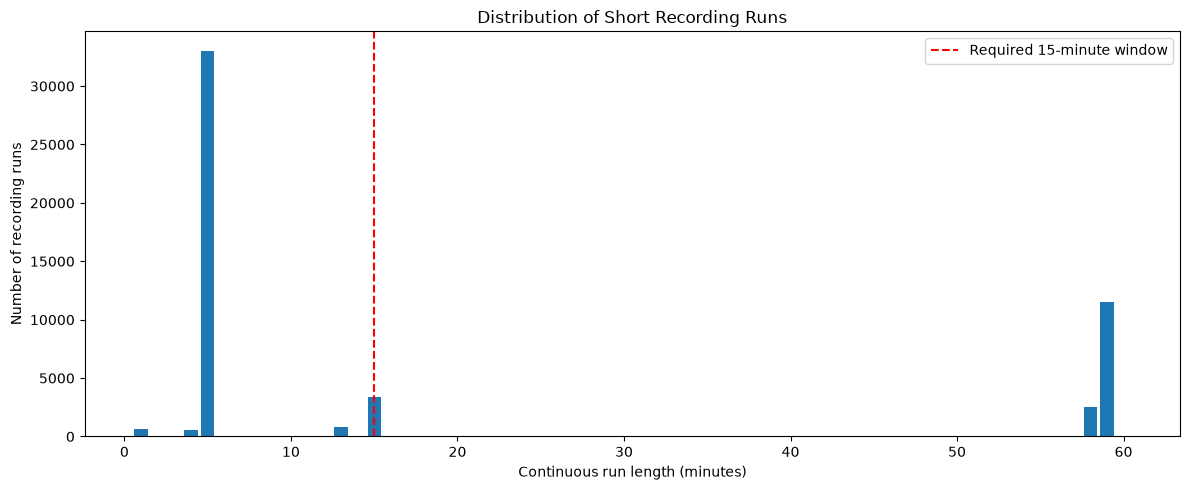

In [21]:
run_distribution = (
    run_length_df.loc[
        run_length_df["run_length_minutes"] <= 60
    ]
    .groupby("run_length_minutes")["number_of_runs"]
    .sum()
)

fig, ax = plt.subplots(figsize=(12, 5))

ax.bar(
    run_distribution.index,
    run_distribution.values
)

ax.axvline(
    15, linestyle="--", color="red",
    label="Required 15-minute window"
)

ax.set_xlabel("Continuous run length (minutes)")
ax.set_ylabel("Number of recording runs")
ax.set_title("Distribution of Short Recording Runs")
ax.legend()

plt.tight_layout()
plt.show()

In [22]:
station_run_summary.to_csv(
    REPORT_DIR / "station_run_length_summary.csv",
    index=False
)

run_length_df.to_csv(
    REPORT_DIR / "recorder_run_length_distribution.csv",
    index=False
)

print("Run-length analysis saved.")

Run-length analysis saved.
